# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it.

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16).
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [1]:
import random
import statistics
import matplotlib.pyplot as plt

SUITS = ("Spades", "Hearts", "Diamonds", "Clubs")
RANKS = ("A", "2", "3", "4", "5", "6", "7", "8", "9", "10", "J", "Q", "K")

class Card:
    def __init__(self, rank, suit=None, plastic=False):
        self.rank = rank
        self.suit = suit
        self.plastic = plastic

    def __repr__(self):
        if self.plastic:
            return "[Plastic cut card]"
        return f"{self.rank} of {self.suit}"

    def blackjack_value(self):
        if self.plastic:
            return 0
        if self.rank == "A":
            return 11
        if self.rank in ("J", "Q", "K", "10"):
            return 10
        return int(self.rank)

class Deck:
    def __init__(self, number_of_decks=6):
        if number_of_decks < 1:
            raise ValueError("At least one deck is required")
        self.number_of_decks = number_of_decks
        self.shuffle()

    def shuffle(self):
        self.cards = [
            Card(rank, suit)
            for _ in range(self.number_of_decks)
            for suit in SUITS
            for rank in RANKS
        ]
        self.cards.append(Card("Plastic", plastic=True))
        random.shuffle(self.cards)
        self.cut_card_drawn = False

    def draw(self):
        if not self.cards:
            self.shuffle()
        card = self.cards.pop()
        if card.plastic:
            self.cut_card_drawn = True
        return card

    def needs_shuffle(self):
        return self.cut_card_drawn or len(self.cards) < 15


In [2]:

deck = Deck(6)

print("Number of cards:", len(deck.cards))
print("Example card:", Card("A", "Spades"))
print("Ace value:", Card("A", "Spades").blackjack_value())


Number of cards: 313
Example card: A of Spades
Ace value: 11


2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook.

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [3]:
class Game:
    def __init__(self, num_decks=6, verbose=True):
        self.deck = Deck(num_decks)
        self.players = []
        self.dealer = Dealer()
        self.round_number = 0
        self.verbose = verbose

    def add_player(self, player):
        self.players.append(player)

    def draw_card(self):
        card = self.deck.draw()
        while card.plastic:
            card = self.deck.draw()
        return card

    def deal_cards(self):
        for player in self.players:
            player.cards = []
        self.dealer.cards = []

        for _ in range(2):
            for player in self.players:
                player.cards.append(self.draw_card())
            self.dealer.cards.append(self.draw_card())

    def play_round(self):
        if self.deck.needs_shuffle():
            self.deck.shuffle()

        self.round_number += 1
        self.deal_cards()

        for player in self.players:
            player.play_turn(self.deck, self)

        self.dealer.play_turn(self.deck, self)
        self.determine_winners()

        if self.deck.needs_shuffle():
            self.deck.shuffle()

    def determine_winners(self):
        dealer_score = self.dealer.calculate_score()
        for player in self.players:
            player_score = player.calculate_score()
            if player_score > 21:
                result = "busts"
                player.chips -= player.bet
            elif dealer_score > 21 or player_score > dealer_score:
                result = "wins"
                player.chips += player.bet
            elif player_score == dealer_score:
                result = "pushes"
            else:
                result = "loses"
                player.chips -= player.bet

            if self.verbose:
                print(f"{player.name}: {player.cards}, score {player_score}; {result}; chips {player.chips}")

        if self.verbose:
            print(f"Dealer: {self.dealer.cards}, score {dealer_score}")
            print("-" * 30)

    def play(self, rounds=1):
        for _ in range(rounds):
            if all(player.chips <= 0 for player in self.players):
                break
            self.play_round()

# Had to LLM because I had not included the verbose function previously, and was an issue for the code as a whole

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [4]:
class Player:
    def __init__(self, name, chips=100, strategy="basic", threshold=2, bet=1):
        self.name = name
        self.chips = chips
        self.strategy = strategy
        self.threshold = threshold
        self.bet = bet
        self.cards = []

    def calculate_score(self):
        score = sum(card.blackjack_value() for card in self.cards)
        aces = sum(1 for card in self.cards if card.rank == "A")
        while score > 21 and aces > 0:
            score -= 10
            aces -= 1
        return score

    def hit(self, deck, game):
        self.cards.append(game.draw_card())

    def play_turn(self, deck, game):
        while self.calculate_score() < 17:
            self.hit(deck, game)

class Dealer(Player):
    def __init__(self):
        super().__init__("Dealer", chips=0)

    def play_turn(self, deck, game):
        while self.calculate_score() < 17:
            self.hit(deck, game)

class HumanPlayer(Player):
    def play_turn(self, deck, game):
        while self.calculate_score() < 21:
            print("Your cards:", self.cards)
            print("Your score:", self.calculate_score())
            choice = input("Hit or stand? ").strip().lower()
            if choice == "hit":
                self.hit(deck, game)
            else:
                break


In [5]:
game = Game(num_decks=6)

player = HumanPlayer("Player 1", 100)
game.add_player(player)

game.play_round()

Your cards: [Q of Spades, K of Diamonds]
Your score: 20
Hit or stand? stand
Player 1: [Q of Spades, K of Diamonds], score 20; loses; chips 99
Dealer: [4 of Diamonds, 8 of Diamonds, 3 of Clubs, 6 of Spades], score 21
------------------------------


5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [6]:
class ComputerPlayer(Player):
    def play_turn(self, deck, game):
        while self.calculate_score() < 17:
            self.hit(deck, game)


In [7]:
game = Game(num_decks=6)

game.add_player(ComputerPlayer("Player 1", 100))
game.add_player(ComputerPlayer("Player 2", 100))
game.add_player(ComputerPlayer("Player 3", 100))

game.play(rounds=3)


Player 1: [4 of Diamonds, 7 of Diamonds, 10 of Hearts], score 21; wins; chips 101
Player 2: [A of Hearts, 2 of Spades, 6 of Clubs], score 19; pushes; chips 100
Player 3: [9 of Clubs, 6 of Clubs, 9 of Clubs], score 24; busts; chips 99
Dealer: [K of Spades, 9 of Hearts], score 19
------------------------------
Player 1: [J of Clubs, 10 of Diamonds], score 20; wins; chips 102
Player 2: [9 of Clubs, Q of Clubs], score 19; pushes; chips 100
Player 3: [K of Clubs, K of Hearts], score 20; wins; chips 100
Dealer: [8 of Spades, A of Diamonds], score 19
------------------------------
Player 1: [5 of Diamonds, K of Diamonds, A of Clubs, A of Diamonds], score 17; pushes; chips 102
Player 2: [4 of Hearts, 2 of Diamonds, 9 of Hearts, K of Clubs], score 25; busts; chips 99
Player 3: [7 of Clubs, 4 of Diamonds, 2 of Diamonds, Q of Diamonds], score 23; busts; chips 99
Dealer: [3 of Clubs, 4 of Spades, J of Diamonds], score 17
------------------------------


6. Implement a new player with the following strategy:

    * Assign each card a value:
        * Cards 2 to 6 are +1
        * Cards 7 to 9 are 0
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

Card values are assigned by `count_value()`: cards 2–6 are +1, 7–9 are 0, and 10 through Ace are −1. `CountingDeck` extends `Deck` so that every time a card is drawn, its value is added to `running_count`, giving the sum of all cards seen since the last shuffle (the count resets when the deck is reshuffled).

The counting player always hits below 12 and always stands at 17 or more. On 12–16 it hits only if the running count is at or below −threshold (very negative); otherwise it stands.

In [30]:
def count_value(card):
    if card.plastic:
        return 0
    if card.rank in ("2", "3", "4", "5", "6"):
        return 1
    if card.rank in ("7", "8", "9"):
        return 0
    return -1

class CountingDeck(Deck):
    def shuffle(self):
        super().shuffle()
        self.running_count = 0

    def draw(self):
        card = super().draw()
        self.running_count += count_value(card)
        return card


class CountingPlayer(Player):
    def play_turn(self, deck, game):
        while True:
            score = self.calculate_score()
            if score < 12:
                self.hit(deck, game)
            elif score >= 17:
                break
            elif deck.running_count <= -self.threshold:
                self.hit(deck, game)
            else:
                break


7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [29]:
counter = CountingPlayer("Counting Player", chips=100, threshold=2)
players = [counter]
for number in range(3):
    players.append(ComputerPlayer(f"Computer {number + 1}", chips=100))

game = Game(num_decks=6, verbose=False)
game.deck = CountingDeck(6)
game.players = players
game.play(rounds=50)

print("Starting chips:", 100)
print("Ending chips:", counter.chips)
print("Net winnings:", counter.chips - 100)
print("Rounds played:", game.round_number)


Starting chips: 100
Ending chips: 109
Net winnings: 9
Rounds played: 50


8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


Average winnings per round: -0.077
Standard deviation: 6.373
Probability of net winning: 0.24
Probability of net losing: 0.72


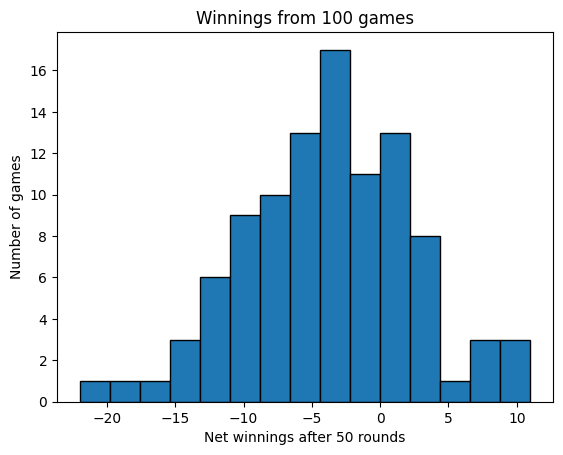

In [21]:
def run_simulation(number_of_games=100, rounds=50, threshold=2, seed=123):
    random.seed(seed)
    winnings = []

    for game_number in range(number_of_games):
        counter = CountingPlayer("Counting Player", chips=100, threshold=threshold)
        players = [counter]
        for number in range(3):
            players.append(ComputerPlayer(f"Computer {number + 1}", chips=100))

        game = Game(num_decks=6, verbose=False)
        game.deck = CountingDeck(6)
        game.players = players
        game.play(rounds=rounds)
        winnings.append(counter.chips - 100)

    return winnings

winnings = run_simulation()
average_per_round = sum(winnings) / (len(winnings) * 50)
standard_deviation = statistics.stdev(winnings)
probability_win = sum(value > 0 for value in winnings) / len(winnings)
probability_loss = sum(value < 0 for value in winnings) / len(winnings)

print("Average winnings per round:", round(average_per_round, 3))
print("Standard deviation:", round(standard_deviation, 3))
print("Probability of net winning:", round(probability_win, 3))
print("Probability of net losing:", round(probability_loss, 3))

plt.hist(winnings, bins=15, edgecolor="black")
plt.xlabel("Net winnings after 50 rounds")
plt.ylabel("Number of games")
plt.title("Winnings from 100 games")
plt.show()


9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

In [11]:
thresholds = [0, 1, 2, 3, 4]
threshold_results = []

for threshold in thresholds:
    winnings = run_simulation(number_of_games=100, rounds=50,
                              threshold=threshold, seed=123)
    average = sum(winnings) / len(winnings)
    threshold_results.append((threshold, average))
    print("Threshold:", threshold, "Average net winnings:", round(average, 2))

best_result = max(threshold_results, key=lambda result: result[1])
print("Best threshold in this test:", best_result[0])
print("This is the best result for these simulations, not a guaranteed optimal strategy.")


Threshold: 0 Average net winnings: -3.34
Threshold: 1 Average net winnings: -4.36
Threshold: 2 Average net winnings: -3.85
Threshold: 3 Average net winnings: -4.1
Threshold: 4 Average net winnings: -4.17
Best threshold in this test: 0
This is the best result for these simulations, not a guaranteed optimal strategy.


10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings.

For a simple alternative strategy, this player hits until the hand is worth at least 12, then stands. Compare its results with the counting strategy over the same number of games.

In [12]:
class CarefulPlayer(Player):
    def play_turn(self, deck, game):
        while self.calculate_score() < 12:
            self.hit(deck, game)

def test_careful_strategy(number_of_games=100, rounds=50, seed=321):
    random.seed(seed)
    results = []

    for game_number in range(number_of_games):
        careful = CarefulPlayer("Careful Player", chips=100)
        players = [careful]
        for number in range(3):
            players.append(ComputerPlayer(f"Computer {number + 1}", chips=100))
        game = Game(num_decks=6, verbose=False)
        game.deck = CountingDeck(6)
        game.players = players
        game.play(rounds=rounds)
        results.append(careful.chips - 100)

    return results

careful_winnings = test_careful_strategy()
print("Average net winnings with careful strategy:", round(sum(careful_winnings) / len(careful_winnings), 2))
print("Average net winnings with counting strategy:", round(sum(run_simulation()) / 100, 2))


Average net winnings with careful strategy: -5.58
Average net winnings with counting strategy: -3.85
